In [28]:
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

import statsmodels.api as sm
from statsmodels.formula.api import ols

from statsmodels.stats.multicomp import pairwise_tukeyhsd

In [29]:
with open("scores.csv", "r") as file:
    for i, line in enumerate(file, start=1):
        print(i, line)

1 "";"student_id";"gender";"parental.level.of.education";"subject";"score"

2 "1";"id_001";"female";"high school";"math";23

3 "2";"id_001";"female";"high school";"language";40

4 "3";"id_002";"female";"high school";"math";68

5 "4";"id_002";"female";"high school";"language";80,5

6 "5";"id_003";"male";"high school";"math";82

7 "6";"id_003";"male";"high school";"language";81

8 "7";"id_004";"female";"high school";"math";58

9 "8";"id_004";"female";"high school";"language";60,5

10 "9";"id_005";"female";"high school";"math";60

11 "10";"id_005";"female";"high school";"language";69

12 "11";"id_006";"male";"high school";"math";79

13 "12";"id_006";"male";"high school";"language";62,5

14 "13";"id_007";"female";"high school";"math";81

15 "14";"id_007";"female";"high school";"language";83

16 "15";"id_008";"female";"high school";"math";34

17 "16";"id_008";"female";"high school";"language";40,5

18 "17";"id_009";"male";"high school";"math";84

19 "18";"id_009";"male";"high school";"langu

In [30]:
df = pd.read_csv("scores.csv", sep=";", decimal=",")
print(df.head(10))

   Unnamed: 0 student_id  gender parental.level.of.education   subject  score
0           1     id_001  female                 high school      math   23.0
1           2     id_001  female                 high school  language   40.0
2           3     id_002  female                 high school      math   68.0
3           4     id_002  female                 high school  language   80.5
4           5     id_003    male                 high school      math   82.0
5           6     id_003    male                 high school  language   81.0
6           7     id_004  female                 high school      math   58.0
7           8     id_004  female                 high school  language   60.5
8           9     id_005  female                 high school      math   60.0
9          10     id_005  female                 high school  language   69.0


In [31]:
df.shape

(972, 6)

In [32]:
df.columns

Index(['Unnamed: 0', 'student_id', 'gender', 'parental.level.of.education',
       'subject', 'score'],
      dtype='object')

In [33]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 972 entries, 0 to 971
Data columns (total 6 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Unnamed: 0                   972 non-null    int64  
 1   student_id                   972 non-null    object 
 2   gender                       972 non-null    object 
 3   parental.level.of.education  972 non-null    object 
 4   subject                      972 non-null    object 
 5   score                        972 non-null    float64
dtypes: float64(1), int64(1), object(4)
memory usage: 45.7+ KB


In [34]:
df.isna().sum()

Unnamed: 0                     0
student_id                     0
gender                         0
parental.level.of.education    0
subject                        0
score                          0
dtype: int64

In [35]:
df.duplicated().sum()

np.int64(0)

In [36]:
df = df.drop(columns=["Unnamed: 0"])
df.head()

,student_id,gender,parental.level.of.education,subject,score
0,id_001,female,high school,math,23.0
1,id_001,female,high school,language,40.0
2,id_002,female,high school,math,68.0
3,id_002,female,high school,language,80.5
4,id_003,male,high school,math,82.0


In [37]:
df.columns

Index(['student_id', 'gender', 'parental.level.of.education', 'subject',
       'score'],
      dtype='object')

In [38]:
df['gender'].value_counts()

gender
female    490
male      482
Name: count, dtype: int64

In [39]:
df['parental.level.of.education'].value_counts()

parental.level.of.education
associate's degree    354
high school           312
bachelor's degree     188
master's degree       118
Name: count, dtype: int64

In [40]:
df['subject'].value_counts()

subject
math        486
language    486
Name: count, dtype: int64

In [41]:
df.groupby('student_id').size().value_counts()

2    486
Name: count, dtype: int64

In [42]:
df.groupby("student_id")["subject"].nunique().value_counts()

subject
2    486
Name: count, dtype: int64

In [43]:
df_wide = df.pivot(
    index=["student_id", "gender", "parental.level.of.education"],
    columns="subject",
    values="score"
).reset_index()

df_wide.head()

subject,student_id,gender,parental.level.of.education,language,math
0,id_001,female,high school,40.0,23.0
1,id_002,female,high school,80.5,68.0
2,id_003,male,high school,81.0,82.0
3,id_004,female,high school,60.5,58.0
4,id_005,female,high school,69.0,60.0


In [44]:
df_wide.columns

Index(['student_id', 'gender', 'parental.level.of.education', 'language',
       'math'],
      dtype='object', name='subject')

In [45]:
df_wide.columns.name = None
df_wide.head()

,student_id,gender,parental.level.of.education,language,math
0,id_001,female,high school,40.0,23.0
1,id_002,female,high school,80.5,68.0
2,id_003,male,high school,81.0,82.0
3,id_004,female,high school,60.5,58.0
4,id_005,female,high school,69.0,60.0


In [46]:
df_wide.shape

(486, 5)

In [47]:
df_wide.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 486 entries, 0 to 485
Data columns (total 5 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   student_id                   486 non-null    object 
 1   gender                       486 non-null    object 
 2   parental.level.of.education  486 non-null    object 
 3   language                     486 non-null    float64
 4   math                         486 non-null    float64
dtypes: float64(2), object(3)
memory usage: 19.1+ KB


In [48]:
df_wide.isna().sum()

student_id                     0
gender                         0
parental.level.of.education    0
language                       0
math                           0
dtype: int64

In [49]:
overall_descriptive = df_wide[["math", "language"]].agg(
    ["count", "mean", "median", "std", "min", "max"]
).round(2)

overall_descriptive

,math,language
count,486.00,486.00
mean,66.38,69.00
median,66.00,70.00
std,15.05,14.45
min,23.00,19.50
max,100.00,100.00


In [50]:
gender_descriptive = df_wide.groupby("gender")[["math", "language"]].agg(
    ["count", "mean", "median", "std", "min", "max"]
).round(2)

gender_descriptive

math                                   language                       \
       count   mean median    std   min    max    count   mean median    std   
gender                                                                         
female   245  63.86   64.0  15.26  23.0  100.0      245  73.00   73.0  14.01   
male     241  68.95   70.0  14.43  30.0  100.0      241  64.93   65.5  13.75   

                     
         min    max  
gender               
female  29.5  100.0  
male    19.5  100.0

In [51]:
parent_education_descriptive = df_wide.groupby("parental.level.of.education")[["math", "language"]].agg(
    ["count", "mean", "median", "std", "min", "max"]
).round(2)

parent_education_descriptive

math                                   language  \
                            count   mean median    std   min    max    count   
parental.level.of.education                                                    
associate's degree            177  67.81   66.0  15.24  26.0  100.0      177   
bachelor's degree              94  68.44   67.0  15.05  29.0  100.0       94   
high school                   156  62.24   63.0  14.04  23.0   94.0      156   
master's degree                59  69.75   73.0  15.15  40.0   95.0       59   

                                                               
                              mean median    std   min    max  
parental.level.of.education                                    
associate's degree           70.02   72.0  14.21  34.5  100.0  
bachelor's degree            72.06   73.0  14.27  40.0  100.0  
high school                  63.53   65.0  13.40  19.5   99.5  
master's degree              75.53   76.0  13.55  44.0  100.0

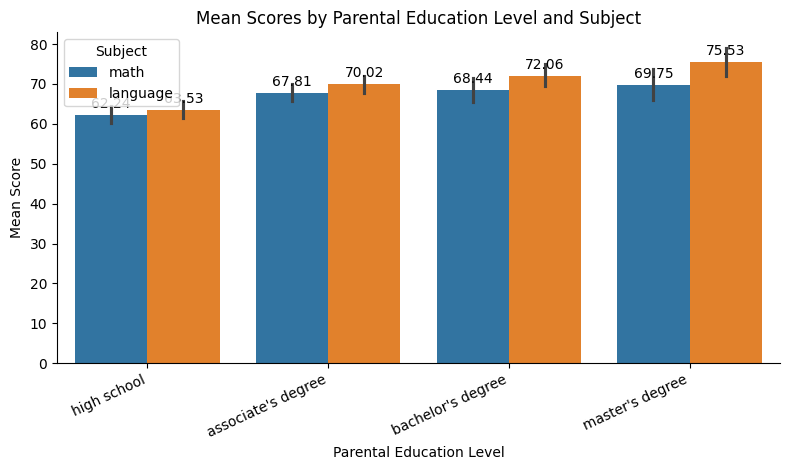

In [77]:
plt.figure(figsize=(8, 4.8))

plot_data = df_wide.melt(
    id_vars=["student_id", "gender", "parental.level.of.education"],
    value_vars=["math", "language"],
    var_name="subject",
    value_name="score"
)

ax = sns.barplot(
    data=plot_data,
    x="parental.level.of.education",
    y="score",
    hue="subject",
    errorbar=("ci", 95)
)

plt.title("Mean Scores by Parental Education Level and Subject")
plt.xlabel("Parental Education Level")
plt.ylabel("Mean Score")
plt.xticks(rotation=25, ha="right")
plt.legend(title="Subject", loc="upper left")

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

# Cleaner frame
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

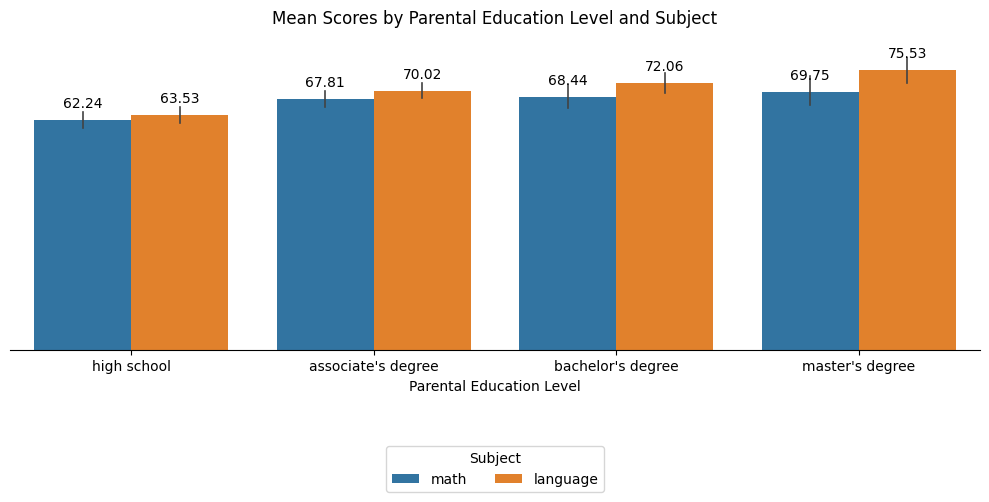

In [87]:
plt.figure(figsize=(10, 5.4))

plot_data = df_wide.melt(
    id_vars=["student_id", "gender", "parental.level.of.education"],
    value_vars=["math", "language"],
    var_name="subject",
    value_name="score"
)

ax = sns.barplot(
    data=plot_data,
    x="parental.level.of.education",
    y="score",
    hue="subject",
    errorbar=("ci", 95),
    err_kws={"linewidth": 1.2}
)

plt.title("Mean Scores by Parental Education Level and Subject")
plt.xlabel("Parental Education Level")
plt.ylabel("")

# Keep category labels horizontal
plt.xticks(rotation=0, ha="center")

# Add values above bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=7)

# Clean frame
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

# Remove y-axis numbers and tick marks
ax.tick_params(axis="y", left=False, labelleft=False)

# Add enough space above values
ax.set_ylim(0, 86)

# Move legend lower
plt.legend(
    title="Subject",
    loc="upper center",
    bbox_to_anchor=(0.5, -0.28),
    ncol=2,
    frameon=True
)

plt.tight_layout()
plt.show()

In [57]:
female_math = df_wide.loc[df_wide["gender"] == "female", "math"]
male_math = df_wide.loc[df_wide["gender"] == "male", "math"]

female_language = df_wide.loc[df_wide["gender"] == "female", "language"]
male_language = df_wide.loc[df_wide["gender"] == "male", "language"]

print("Female math:", len(female_math))
print("Male math:", len(male_math))
print("Female language:", len(female_language))
print("Male language:", len(male_language))

Female math: 245
Male math: 241
Female language: 245
Male language: 241


In [58]:
math_ttest = stats.ttest_ind(
    female_math,
    male_math,
    equal_var=False
)

language_ttest = stats.ttest_ind(
    female_language,
    male_language,
    equal_var=False
)

print("Math t-test:")
print(math_ttest)

print("\nLanguage t-test:")
print(language_ttest)

Math t-test:
TtestResult(statistic=np.float64(-3.7782415760861223), pvalue=np.float64(0.00017765367995423834), df=np.float64(483.2323215504577))

Language t-test:
TtestResult(statistic=np.float64(6.409643311669151), pvalue=np.float64(3.4667623351405716e-10), df=np.float64(483.99755070317576))


In [59]:
def cohens_d(group1, group2):
    n1 = len(group1)
    n2 = len(group2)
    
    s1 = group1.std(ddof=1)
    s2 = group2.std(ddof=1)
    
    pooled_sd = (((n1 - 1) * s1**2 + (n2 - 1) * s2**2) / (n1 + n2 - 2)) ** 0.5
    
    d = (group1.mean() - group2.mean()) / pooled_sd
    
    return d


math_d = cohens_d(female_math, male_math)
language_d = cohens_d(female_language, male_language)

print("Cohen's d for math:", round(math_d, 3))
print("Cohen's d for language:", round(language_d, 3))

Cohen's d for math: -0.343
Cohen's d for language: 0.581


In [60]:
math_anova_model = ols(
    "math ~ C(Q('parental.level.of.education'))",
    data=df_wide
).fit()

math_anova_table = sm.stats.anova_lm(
    math_anova_model,
    typ=2
)

math_anova_table

,sum_sq,df,F,PR(>F)
C(Q('parental.level.of.education')),4098.683680,3.0,6.222926,0.000375
Residual,105821.894509,482.0,NaN,NaN


In [61]:
language_anova_model = ols(
    "language ~ C(Q('parental.level.of.education'))",
    data=df_wide
).fit()

language_anova_table = sm.stats.anova_lm(
    language_anova_model,
    typ=2
)

language_anova_table

,sum_sq,df,F,PR(>F)
C(Q('parental.level.of.education')),8240.860082,3.0,14.24059,6.617864e-09
Residual,92975.889404,482.0,NaN,NaN


In [62]:
math_tukey = pairwise_tukeyhsd(

    endog=df_wide["math"],

    groups=df_wide["parental.level.of.education"],

    alpha=0.05

)

print(math_tukey)

            Multiple Comparison of Means - Tukey HSD, FWER=0.05             
      group1             group2      meandiff p-adj   lower    upper  reject
----------------------------------------------------------------------------
associate's degree bachelor's degree   0.6226 0.9877  -4.2525  5.4977  False
associate's degree       high school    -5.57 0.0037  -9.7649 -1.3751   True
associate's degree   master's degree   1.9322 0.8217  -3.8102  7.6746  False
 bachelor's degree       high school  -6.1926 0.0079 -11.1802  -1.205   True
 bachelor's degree   master's degree   1.3096 0.9512   -5.035  7.6542  False
       high school   master's degree   7.5022 0.0055   1.6639 13.3404   True
----------------------------------------------------------------------------


In [63]:
language_tukey = pairwise_tukeyhsd(
    endog=df_wide["language"],
    groups=df_wide["parental.level.of.education"],
    alpha=0.05
)

print(language_tukey)

            Multiple Comparison of Means - Tukey HSD, FWER=0.05             
      group1             group2      meandiff p-adj   lower    upper  reject
----------------------------------------------------------------------------
associate's degree bachelor's degree   2.0359 0.6596  -2.5337  6.6055  False
associate's degree       high school  -6.4905 0.0001 -10.4226 -2.5585   True
associate's degree   master's degree   5.5028 0.0429   0.1202 10.8854   True
 bachelor's degree       high school  -8.5265    0.0 -13.2016 -3.8514   True
 bachelor's degree   master's degree   3.4669 0.4365  -2.4802   9.414  False
       high school   master's degree  11.9934    0.0    6.521 17.4658   True
----------------------------------------------------------------------------


In [64]:
# Eta-squared for Mathematics ANOVA
math_ss_between = math_anova_table.loc["C(Q('parental.level.of.education'))", "sum_sq"]
math_ss_residual = math_anova_table.loc["Residual", "sum_sq"]
math_ss_total = math_ss_between + math_ss_residual

math_eta_squared = math_ss_between / math_ss_total


# Eta-squared for Language ANOVA
language_ss_between = language_anova_table.loc["C(Q('parental.level.of.education'))", "sum_sq"]
language_ss_residual = language_anova_table.loc["Residual", "sum_sq"]
language_ss_total = language_ss_between + language_ss_residual

language_eta_squared = language_ss_between / language_ss_total


print("Eta-squared for Mathematics:", round(math_eta_squared, 3))
print("Eta-squared for Language:", round(language_eta_squared, 3))

Eta-squared for Mathematics: 0.037
Eta-squared for Language: 0.081


In [65]:
math_gender_levene = stats.levene(female_math, male_math)

language_gender_levene = stats.levene(female_language, male_language)

print("Levene test for math by gender:")

print(math_gender_levene)

print("\nLevene test for language by gender:")

print(language_gender_levene)

Levene test for math by gender:
LeveneResult(statistic=np.float64(0.006027226933929371), pvalue=np.float64(0.9381503111997892))

Levene test for language by gender:
LeveneResult(statistic=np.float64(0.15959812692149067), pvalue=np.float64(0.6897030079546667))


In [66]:
math_parent_groups = [
    group["math"].values
    for name, group in df_wide.groupby("parental.level.of.education")
]

language_parent_groups = [
    group["language"].values
    for name, group in df_wide.groupby("parental.level.of.education")
]

math_parent_levene = stats.levene(*math_parent_groups)
language_parent_levene = stats.levene(*language_parent_groups)

print("Levene test for math by parental education:")
print(math_parent_levene)

print("\nLevene test for language by parental education:")
print(language_parent_levene)

Levene test for math by parental education:
LeveneResult(statistic=np.float64(1.27477023968727), pvalue=np.float64(0.28235859623805004))

Levene test for language by parental education:
LeveneResult(statistic=np.float64(0.16931878485834423), pvalue=np.float64(0.9170829330433247))


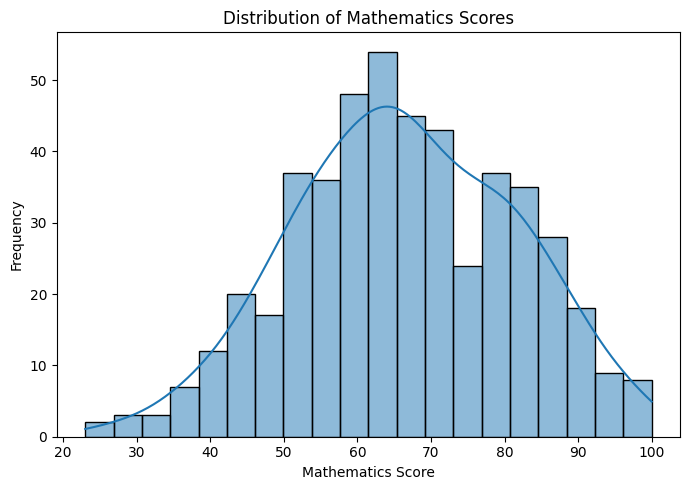

In [67]:
plt.figure(figsize=(7, 5))

sns.histplot(
    data=df_wide,
    x="math",
    bins=20,
    kde=True
)

plt.title("Distribution of Mathematics Scores")
plt.xlabel("Mathematics Score")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

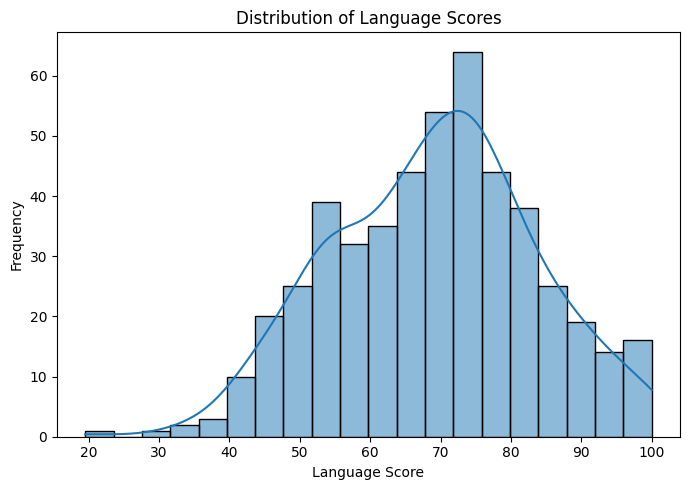

In [68]:
plt.figure(figsize=(7, 5))

sns.histplot(
    data=df_wide,
    x="language",
    bins=20,
    kde=True
)

plt.title("Distribution of Language Scores")
plt.xlabel("Language Score")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

In [69]:
results_summary = pd.DataFrame({
    "Research question": [
        "Gender difference in Mathematics",
        "Gender difference in Language",
        "Parental education difference in Mathematics",
        "Parental education difference in Language"
    ],
    "Test used": [
        "Welch t-test",
        "Welch t-test",
        "One-way ANOVA",
        "One-way ANOVA"
    ],
    "Test statistic": [
        round(math_ttest.statistic, 3),
        round(language_ttest.statistic, 3),
        round(math_anova_table.loc["C(Q('parental.level.of.education'))", "F"], 3),
        round(language_anova_table.loc["C(Q('parental.level.of.education'))", "F"], 3)
    ],
    "p-value": [
        math_ttest.pvalue,
        language_ttest.pvalue,
        math_anova_table.loc["C(Q('parental.level.of.education'))", "PR(>F)"],
        language_anova_table.loc["C(Q('parental.level.of.education'))", "PR(>F)"]
    ],
    "Effect size": [
        round(math_d, 3),
        round(language_d, 3),
        round(math_eta_squared, 3),
        round(language_eta_squared, 3)
    ],
    "Significant at 0.05?": [
        math_ttest.pvalue < 0.05,
        language_ttest.pvalue < 0.05,
        math_anova_table.loc["C(Q('parental.level.of.education'))", "PR(>F)"] < 0.05,
        language_anova_table.loc["C(Q('parental.level.of.education'))", "PR(>F)"] < 0.05
    ]
})

results_summary

,Research question,Test used,Test statistic,p-value,Effect size,Significant at 0.05?
0,Gender difference in Mathematics,Welch t-test,-3.778,1.776537e-04,-0.343,True
1,Gender difference in Language,Welch t-test,6.410,3.466762e-10,0.581,True
2,Parental education difference in Mathematics,One-way ANOVA,6.223,3.750888e-04,0.037,True
3,Parental education difference in Language,One-way ANOVA,14.241,6.617864e-09,0.081,True


In [70]:
# Convert Tukey HSD results into DataFrames
math_tukey_df = pd.DataFrame(
    data=math_tukey._results_table.data[1:],
    columns=math_tukey._results_table.data[0]
)

language_tukey_df = pd.DataFrame(
    data=language_tukey._results_table.data[1:],
    columns=language_tukey._results_table.data[0]
)

# Keep only significant comparisons
math_significant = math_tukey_df[math_tukey_df["reject"] == True].copy()
language_significant = language_tukey_df[language_tukey_df["reject"] == True].copy()

# Add subject labels
math_significant["subject"] = "Mathematics"
language_significant["subject"] = "Language"

# Combine both subjects into one table
tukey_summary = pd.concat(
    [math_significant, language_significant],
    ignore_index=True
)

# Select and rename useful columns
tukey_summary = tukey_summary[
    ["subject", "group1", "group2", "meandiff", "p-adj", "lower", "upper"]
].rename(columns={
    "subject": "Subject",
    "group1": "Group 1",
    "group2": "Group 2",
    "meandiff": "Mean difference",
    "p-adj": "Adjusted p-value",
    "lower": "CI lower",
    "upper": "CI upper"
})

tukey_summary

,Subject,Group 1,Group 2,Mean difference,Adjusted p-value,CI lower,CI upper
0,Mathematics,associate's degree,high school,-5.5700,0.0037,-9.7649,-1.3751
1,Mathematics,bachelor's degree,high school,-6.1926,0.0079,-11.1802,-1.2050
2,Mathematics,high school,master's degree,7.5022,0.0055,1.6639,13.3404
3,Language,associate's degree,high school,-6.4905,0.0001,-10.4226,-2.5585
4,Language,associate's degree,master's degree,5.5028,0.0429,0.1202,10.8854
5,Language,bachelor's degree,high school,-8.5265,0.0000,-13.2016,-3.8514
6,Language,high school,master's degree,11.9934,0.0000,6.5210,17.4658


In [71]:
anova_term = "C(Q('parental.level.of.education'))"

results_summary_report = pd.DataFrame({
    "Research question": [
        "Gender difference in Mathematics",
        "Gender difference in Language",
        "Parental education difference in Mathematics",
        "Parental education difference in Language"
    ],
    "Test used": [
        "Welch t-test",
        "Welch t-test",
        "One-way ANOVA",
        "One-way ANOVA"
    ],
    "Statistic": [
        f"t = {math_ttest.statistic:.2f}",
        f"t = {language_ttest.statistic:.2f}",
        f"F = {math_anova_table.loc[anova_term, 'F']:.2f}",
        f"F = {language_anova_table.loc[anova_term, 'F']:.2f}"
    ],
    "p-value": [
        "p < .001",
        "p < .001",
        "p < .001",
        "p < .001"
    ],
    "Effect size": [
        f"d = {math_d:.3f}",
        f"d = {language_d:.3f}",
        f"η² = {math_eta_squared:.3f}",
        f"η² = {language_eta_squared:.3f}"
    ],
    "Conclusion": [
        "Significant",
        "Significant",
        "Significant",
        "Significant"
    ]
})

results_summary_report

,Research question,Test used,Statistic,p-value,Effect size,Conclusion
0,Gender difference in Mathematics,Welch t-test,t = -3.78,p < .001,d = -0.343,Significant
1,Gender difference in Language,Welch t-test,t = 6.41,p < .001,d = 0.581,Significant
2,Parental education difference in Mathematics,One-way ANOVA,F = 6.22,p < .001,η² = 0.037,Significant
3,Parental education difference in Language,One-way ANOVA,F = 14.24,p < .001,η² = 0.081,Significant
